# Algorithms — Implementation & Empirical Analysis
### Discrete Mathematics (MSc IT) — Assignment

| | |
|---|---|
| **Student** | Solanki Ruchit M. |
| **Student ID** | 202612085 |
| **Course** | MSc IT |
| **Subject** | Discrete Mathematics |
| **Instructor** | Prof. Gopinath Panda |
| **Reference** | K. H. Rosen, *Discrete Mathematics and Its Applications*, 8th ed., **Chapter 3 — Algorithms** |

This notebook implements the algorithms of Rosen, Chapter 3, and **verifies the
complexity claims experimentally**. Every algorithm counts its basic operations,
so the observed counts can be compared with the theoretical growth rates
$O(1), O(\log n), O(n), O(n\log n), O(n^2), O(2^n)$.

## 0.  Environment setup
Import libraries and define a consistent plotting style.

In [1]:
import math, time, random
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7.6, 3.3), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
    "axes.titleweight": "bold",
})
random.seed(202612085)
np.random.seed(202612085)
print("Python environment ready.  numpy", np.__version__)

Python environment ready.  numpy 2.2.4


## 1.  Searching algorithms

**Linear search** scans the list from left to right — $\Theta(n)$.
**Binary search** halves a *sorted* interval at every step — $\Theta(\log n)$.

In [2]:
def linear_search(a, x):
    """Return (index, comparisons). -1 means 'not found'."""
    comparisons = 0
    for i, v in enumerate(a):
        comparisons += 1
        if v == x:
            return i, comparisons
    return -1, comparisons


def binary_search(a, x):
    """Binary search on a sorted list. Return (index, comparisons)."""
    lo, hi = 0, len(a) - 1
    comparisons = 0
    while lo <= hi:
        mid = (lo + hi) // 2
        comparisons += 1
        if a[mid] == x:
            return mid, comparisons
        elif a[mid] < x:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1, comparisons

# quick correctness demo
data = [3, 8, 14, 21, 27, 33, 46, 52, 61, 75, 88, 96]
for key in (61, 3, 50):
    print(f"key={key:3d}  linear -> {linear_search(data, key)}   binary -> {binary_search(data, key)}")

key= 61  linear -> (8, 9)   binary -> (8, 2)
key=  3  linear -> (0, 1)   binary -> (0, 3)
key= 50  linear -> (-1, 12)   binary -> (-1, 4)


### 1.1  Empirical comparison count

Worst case (the key is **absent**): linear search does $n$ comparisons,
binary search does $\lfloor \log_2 n \rfloor + 1$. The gap is the whole point of
the $\Theta(\log n)$ class.

      n |   linear (n) |   binary (log n+1)
--------------------------------------------
     10 |           10 |                  3
     50 |           50 |                  5
    100 |          100 |                  6
    500 |          500 |                  8
   1000 |         1000 |                  9
   5000 |         5000 |                 12
  10000 |        10000 |                 13


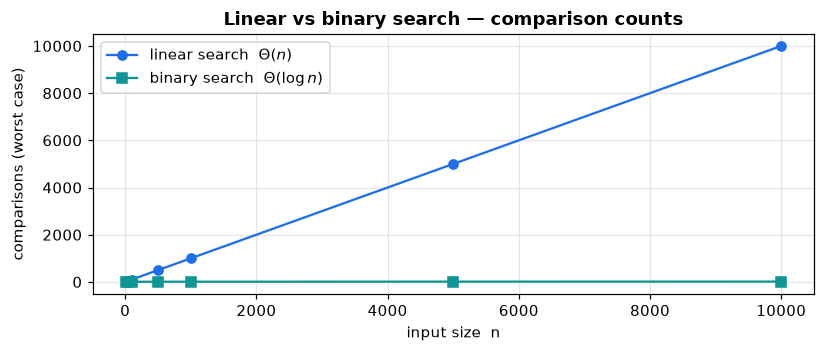

In [3]:
sizes = [10, 50, 100, 500, 1000, 5000, 10000]
lin_counts, bin_counts = [], []
for n in sizes:
    arr = sorted(random.sample(range(1, 10 * n), n))
    missing = -1                              # guaranteed absent -> worst case
    _, c1 = linear_search(arr, missing)
    _, c2 = binary_search(arr, missing)
    lin_counts.append(c1)
    bin_counts.append(c2)

print(f"{'n':>7} | {'linear (n)':>12} | {'binary (log n+1)':>18}")
print("-" * 44)
for n, c1, c2 in zip(sizes, lin_counts, bin_counts):
    print(f"{n:>7} | {c1:>12} | {c2:>18}")

plt.plot(sizes, lin_counts, "o-", label=r"linear search  $\Theta(n)$", color="#1F6FEB")
plt.plot(sizes, bin_counts, "s-", label=r"binary search  $\Theta(\log n)$", color="#0E9594")
plt.xlabel("input size  n"); plt.ylabel("comparisons (worst case)")
plt.title("Linear vs binary search — comparison counts")
plt.legend(); plt.tight_layout(); plt.show()

## 2.  Sorting algorithms

Bubble / insertion / selection sort are $\Theta(n^2)$; merge sort is
$\Theta(n\log n)$.

In [4]:
def bubble_sort(a):
    a = a[:]; comps = 0; n = len(a)
    for i in range(n - 1):
        for j in range(n - 1 - i):
            comps += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
    return a, comps


def insertion_sort(a):
    a = a[:]; comps = 0
    for j in range(1, len(a)):
        key = a[j]; i = j - 1
        while i >= 0:
            comps += 1
            if a[i] > key:
                a[i + 1] = a[i]; i -= 1
            else:
                break
        a[i + 1] = key
    return a, comps


def selection_sort(a):
    a = a[:]; comps = 0; n = len(a)
    for i in range(n - 1):
        m = i
        for j in range(i + 1, n):
            comps += 1
            if a[j] < a[m]:
                m = j
        a[i], a[m] = a[m], a[i]
    return a, comps


def merge_sort(a):
    counter = [0]
    def _ms(arr):
        if len(arr) <= 1:
            return arr
        mid = len(arr) // 2
        L, R = _ms(arr[:mid]), _ms(arr[mid:])
        merged, i, j = [], 0, 0
        while i < len(L) and j < len(R):
            counter[0] += 1
            if L[i] <= R[j]:
                merged.append(L[i]); i += 1
            else:
                merged.append(R[j]); j += 1
        merged.extend(L[i:]); merged.extend(R[j:])
        return merged
    return _ms(a), counter[0]

demo = [29, 10, 14, 37, 13]
for name, fn in [("bubble", bubble_sort), ("insertion", insertion_sort),
                 ("selection", selection_sort), ("merge", merge_sort)]:
    out, c = fn(demo)
    print(f"{name:>10}: {out}   comparisons = {c}")

    bubble: [10, 13, 14, 29, 37]   comparisons = 10
 insertion: [10, 13, 14, 29, 37]   comparisons = 8
 selection: [10, 13, 14, 29, 37]   comparisons = 10
     merge: [10, 13, 14, 29, 37]   comparisons = 8


### 2.1  Verification of the closed form

For bubble sort the exact number of comparisons is $n(n-1)/2$; for a
reverse-sorted input, insertion and selection sort also reach $\Theta(n^2)$,
while merge sort stays at $\Theta(n\log n)$.

In [5]:
for n in [10, 50, 100, 200]:
    worst = list(range(n, 0, -1))                 # reverse sorted
    b, cb = bubble_sort(worst)
    i, ci = insertion_sort(worst)
    s, cs = selection_sort(worst)
    m, cm = merge_sort(worst)
    assert b == i == s == m == sorted(worst), "sorting failed!"
    assert cb == n * (n - 1) // 2, "bubble-sort closed form failed!"
    print(f"n={n:>4}  bubble={cb:>7}  insertion={ci:>7}  selection={cs:>7}  "
          f"merge={cm:>6}   n(n-1)/2={n*(n-1)//2}")
print("\nAll correctness assertions passed.")

n=  10  bubble=     45  insertion=     45  selection=     45  merge=    19   n(n-1)/2=45
n=  50  bubble=   1225  insertion=   1225  selection=   1225  merge=   153   n(n-1)/2=1225
n= 100  bubble=   4950  insertion=   4950  selection=   4950  merge=   356   n(n-1)/2=4950
n= 200  bubble=  19900  insertion=  19900  selection=  19900  merge=   812   n(n-1)/2=19900

All correctness assertions passed.


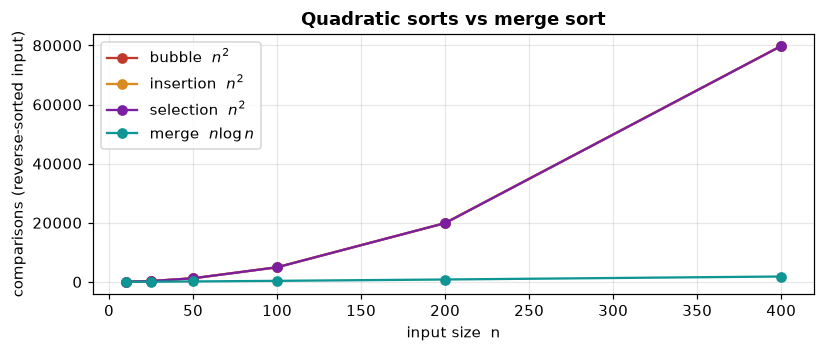

In [6]:
sizes = [10, 25, 50, 100, 200, 400]
res = {name: [] for name in ["bubble", "insertion", "selection", "merge"]}
for n in sizes:
    worst = list(range(n, 0, -1))
    res["bubble"].append(bubble_sort(worst)[1])
    res["insertion"].append(insertion_sort(worst)[1])
    res["selection"].append(selection_sort(worst)[1])
    res["merge"].append(merge_sort(worst)[1])

styles = {"bubble": ("#C0392B", r"bubble  $n^2$"),
          "insertion": ("#D98A20", r"insertion  $n^2$"),
          "selection": ("#7B1FA2", r"selection  $n^2$"),
          "merge": ("#0E9594", r"merge  $n\log n$")}
for name, vals in res.items():
    c, lab = styles[name]
    plt.plot(sizes, vals, "o-", color=c, label=lab)
plt.xlabel("input size  n"); plt.ylabel("comparisons (reverse-sorted input)")
plt.title("Quadratic sorts vs merge sort")
plt.legend(); plt.tight_layout(); plt.show()

## 3.  Greedy algorithm — change-making

Take the largest coin that fits, repeatedly. Fast, but its optimality depends on
the coin system.

In [7]:
def greedy_change(amount, coins=(25, 10, 5, 1)):
    counts, remaining = {}, amount
    for c in coins:
        counts[c] = 0
        while remaining >= c:
            remaining -= c
            counts[c] += 1
    return counts, remaining

for amt in (87, 63, 41):
    counts, left = greedy_change(amt)
    used = {k: v for k, v in counts.items() if v}
    print(f"amount {amt:>3} -> {used}   total coins = {sum(used.values())}   leftover = {left}")

amount  87 -> {25: 3, 10: 1, 1: 2}   total coins = 6   leftover = 0
amount  63 -> {25: 2, 10: 1, 1: 3}   total coins = 6   leftover = 0
amount  41 -> {25: 1, 10: 1, 5: 1, 1: 1}   total coins = 4   leftover = 0


## 4.  Recursive algorithms

**Factorial** is $\Theta(n)$; **Towers of Hanoi** satisfies
$M(n) = 2M(n-1)+1$, hence $M(n) = 2^n - 1$ moves — exponential.

In [8]:
def factorial(n):
    return 1 if n == 0 else n * factorial(n - 1)

hanoi_moves = [0]
def hanoi(n, src="A", dst="C", aux="B"):
    if n == 1:
        hanoi_moves[0] += 1
    else:
        hanoi(n - 1, src, aux, dst)
        hanoi_moves[0] += 1
        hanoi(n - 1, aux, dst, src)

print("factorials:", [factorial(k) for k in range(11)])
print(f"{'n':>3} | {'2^n - 1':>10} | {'moves counted':>14}")
print("-" * 34)
for n in range(1, 13):
    hanoi_moves[0] = 0
    hanoi(n)
    assert hanoi_moves[0] == 2 ** n - 1
    print(f"{n:>3} | {2**n - 1:>10} | {hanoi_moves[0]:>14}")

factorials: [1, 1, 2, 6, 24, 120, 720, 5040, 40320, 362880, 3628800]
  n |    2^n - 1 |  moves counted
----------------------------------
  1 |          1 |              1
  2 |          3 |              3
  3 |          7 |              7
  4 |         15 |             15
  5 |         31 |             31
  6 |         63 |             63
  7 |        127 |            127
  8 |        255 |            255
  9 |        511 |            511
 10 |       1023 |           1023
 11 |       2047 |           2047
 12 |       4095 |           4095


## 5.  Growth of functions (Rosen §3.2)

Left: linear scale. Right: logarithmic scale, where the powers become straight
lines — the standard way to compare growth rates.

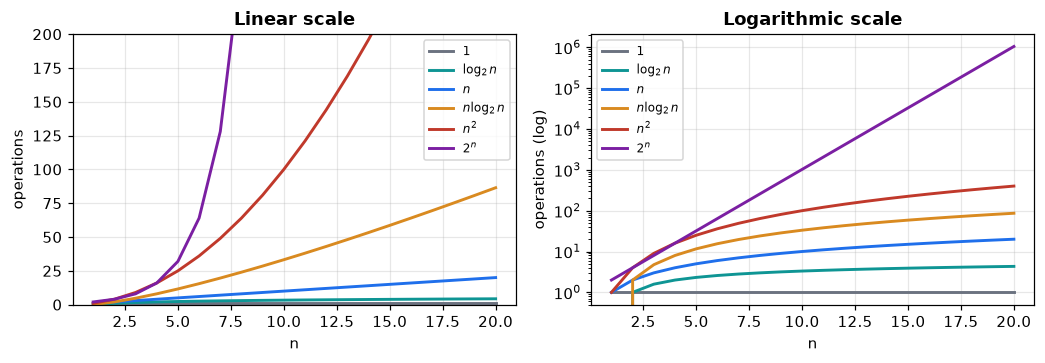

In [9]:
n = np.arange(1, 21)
curves = [
    (np.ones_like(n, dtype=float), r"$1$", "#6B7280"),
    (np.log2(n), r"$\log_2 n$", "#0E9594"),
    (n, r"$n$", "#1F6FEB"),
    (n * np.log2(n), r"$n\log_2 n$", "#D98A20"),
    (n ** 2, r"$n^2$", "#C0392B"),
    (2.0 ** n, r"$2^n$", "#7B1FA2"),
]
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.4))
for y, lab, c in curves:
    ax[0].plot(n, y, label=lab, color=c, lw=1.9)
ax[0].set_ylim(0, 200); ax[0].set_xlabel("n"); ax[0].set_ylabel("operations")
ax[0].set_title("Linear scale"); ax[0].legend(fontsize=8)
for y, lab, c in curves:
    ax[1].plot(n, y, label=lab, color=c, lw=1.9)
ax[1].set_yscale("log"); ax[1].set_xlabel("n"); ax[1].set_ylabel("operations (log)")
ax[1].set_title("Logarithmic scale"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### 5.1  Verifying a big-$O statement

Claim: $f(n) = 3n^2 + 2n + 5$ is $O(n^2)$. Because $2n \le 2n^2$ and
$5 \le 5n^2$ for $n \ge 1$, we get $f(n) \le 10n^2$ — the witnesses are
$C = 10$, $k = 1$.

In [10]:
print(f"{'n':>4} | {'f(n)=3n^2+2n+5':>16} | {'10n^2':>12} | {'f(n)/n^2':>9} | ok")
print("-" * 62)
for k in range(1, 13):
    f = 3 * k**2 + 2 * k + 5
    bound = 10 * k**2
    print(f"{k:>4} | {f:>16} | {bound:>12} | {f/k**2:>9.2f} | {f <= bound}")
print("\nBy the definition, f(n) = O(n^2) with witnesses C = 10 and k = 1.")

   n |   f(n)=3n^2+2n+5 |        10n^2 |  f(n)/n^2 | ok
--------------------------------------------------------------
   1 |               10 |           10 |     10.00 | True
   2 |               21 |           40 |      5.25 | True
   3 |               38 |           90 |      4.22 | True
   4 |               61 |          160 |      3.81 | True
   5 |               90 |          250 |      3.60 | True
   6 |              125 |          360 |      3.47 | True
   7 |              166 |          490 |      3.39 | True
   8 |              213 |          640 |      3.33 | True
   9 |              266 |          810 |      3.28 | True
  10 |              325 |         1000 |      3.25 | True
  11 |              390 |         1210 |      3.22 | True
  12 |              461 |         1440 |      3.20 | True

By the definition, f(n) = O(n^2) with witnesses C = 10 and k = 1.


## 6.  Summary

| Algorithm | Paradigm | Worst case | Rosen |
|---|---|---|---|
| Linear search | scan | $O(n)$ | §3.1 |
| Binary search | halve interval | $O(\log n)$ | §3.1 |
| Bubble sort | exchange | $O(n^2)$ | §3.1 |
| Insertion sort | incremental | $O(n^2)$ | §3.1 |
| Selection sort | incremental | $O(n^2)$ | §3.1 |
| Merge sort | divide & conquer | $O(n\log n)$ | §3.1 |
| Greedy change | greedy | $O(n)$ | §3.1 |
| Factorial (rec.) | recursion | $O(n)$ | §5.3 |
| Towers of Hanoi | recursion | $O(2^n)$ | §8.1 |

## 7.  Conclusion

The experiments confirm the theory exactly: binary search needs
$\lfloor \log_2 n\rfloor + 1$ comparisons, bubble sort always executes
$n(n-1)/2$ of them, and merge sort stays far below the quadratic sorts. The
$\log$ scale makes the growth classes visible: exponential and quadratic
functions eventually dominate every polynomial, which is precisely why the
$O$-notation of §3.2 and the complexity analysis of §3.3 decide whether a
problem is computationally **tractable**.

## References
1. K. H. Rosen, *Discrete Mathematics and Its Applications*, 8th ed., McGraw-Hill, 2019 — Chapter 3, pp. 191–242.
2. T. H. Cormen et al., *Introduction to Algorithms*, 3rd ed., MIT Press, 2009.
3. D. E. Knuth, *The Art of Computer Programming, Vol. 1*, 3rd ed., Addison-Wesley, 1997.
4. R. Sedgewick & K. Wayne, *Algorithms*, 4th ed., Addison-Wesley, 2011.